# Voyage Analytics — 03. Travel & Hotel Package Recommendation System

## Project Overview
This notebook builds and evaluates a realistic, data-grounded **Travel & Hotel Recommendation System** using all three capstone datasets (`hotels.csv`, `flights.csv`, and `users.csv`).

### Why This Redesign Matters
A direct audit of `hotels.csv` reveals that **each of the 9 destinations contains only ONE hotel with ONE fixed daily price** (e.g., *Florianopolis (SC)* -> *Hotel A* at \$313.02/day).
- A naive hotel-only filter (`place == destination` + deduplicate by `name`) can **never return more than 1 hotel**, regardless of `top_n`.
- Instead of pretending multiple hotels exist per city, we join `hotels.csv`, round-trip `flights.csv` (via `travelCode`), and `users.csv` (via `userCode`) to create **40,552 complete travel bookings** spanning **1,568 distinct round-trip Flight + Hotel packages**, and combine:
  1. **Collaborative Filtering (User-Based Cosine Similarity, Item-Based CF, TruncatedSVD)** — honestly evaluated and analyzed with its real dataset limitations.
  2. **Hybrid Travel Package & Destination Recommendation Engine** — considering destination (optional), origin, trip duration, total budget, flight class preference, popularity, and user booking history.

## 1. Environment & Google Colab Compatibility Setup

In [1]:
# Optional: Uncomment when running in Google Colab if packages are missing.
# !pip install -q scikit-learn pandas numpy matplotlib seaborn

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

IN_COLAB = "google.colab" in sys.modules
print(f"Running in Google Colab: {IN_COLAB}")
print(f"Python {sys.version.split()[0]} | Pandas {pd.__version__} | NumPy {np.__version__}")

Running in Google Colab: False
Python 3.13.14 | Pandas 3.1.1 | NumPy 2.5.5


In [2]:
def resolve_dataset_dir() -> Path:
    """Locate travel_capstone_dataset directory across local Jupyter and Google Colab."""
    cwd = Path.cwd()
    candidates = [
        cwd / "travel_capstone_dataset",
        cwd.parent / "travel_capstone_dataset",
        Path("/content/travel_capstone_dataset"),
        Path("/content/voyage-analytics-mlops/travel_capstone_dataset"),
        Path("/content/drive/MyDrive/voyage-analytics-mlops/travel_capstone_dataset"),
        Path("/content"),
    ]
    for folder in candidates:
        if (folder / "hotels.csv").exists() and (folder / "flights.csv").exists() and (folder / "users.csv").exists():
            return folder

    raise FileNotFoundError(
        "Could not locate hotels.csv, flights.csv, and users.csv. "
        "In Google Colab, upload all three files to /content/travel_capstone_dataset/."
    )

DATA_DIR = resolve_dataset_dir()
hotels = pd.read_csv(DATA_DIR / "hotels.csv")
flights = pd.read_csv(DATA_DIR / "flights.csv")
users = pd.read_csv(DATA_DIR / "users.csv")

hotels["date"] = pd.to_datetime(hotels["date"], format="%m/%d/%Y")
flights["date"] = pd.to_datetime(flights["date"], format="%m/%d/%Y")

print(f"hotels.csv : {hotels.shape[0]:,} rows x {hotels.shape[1]} cols | nulls={int(hotels.isna().sum().sum())} | dups={hotels.duplicated().sum()}")
print(f"flights.csv: {flights.shape[0]:,} rows x {flights.shape[1]} cols | nulls={int(flights.isna().sum().sum())} | dups={flights.duplicated().sum()}")
print(f"users.csv  : {users.shape[0]:,} rows x {users.shape[1]} cols | nulls={int(users.isna().sum().sum())} | dups={users.duplicated().sum()}")

hotels.csv : 40,552 rows x 8 cols | nulls=0 | dups=0
flights.csv: 271,888 rows x 10 cols | nulls=0 | dups=0
users.csv  : 1,340 rows x 5 cols | nulls=0 | dups=0


## 2. Dataset Audit: Exposing the 1-Hotel-Per-City Limitation
Before designing any recommendation algorithm, we inspect the exact mapping between destinations (`place`), hotel names (`name`), and daily prices (`price`).

In [3]:
city_hotel_audit = (
    hotels.groupby(["place", "name"])
    .agg(
        bookings=("travelCode", "count"),
        unique_users=("userCode", "nunique"),
        unique_daily_prices=("price", "nunique"),
        price_per_day=("price", "first"),
        min_days=("days", "min"),
        max_days=("days", "max"),
        avg_days=("days", "mean"),
        avg_hotel_total=("total", "mean"),
    )
    .reset_index()
    .sort_values("bookings", ascending=False)
)

hotels_per_city = hotels.groupby("place")["name"].nunique()
print("Unique destinations in hotels.csv:", hotels["place"].nunique())
print("Unique hotel names in hotels.csv :", hotels["name"].nunique())
print("Max hotels in ANY single city    :", int(hotels_per_city.max()))
print("Min hotels in ANY single city    :", int(hotels_per_city.min()))
display(city_hotel_audit)

Unique destinations in hotels.csv: 9
Unique hotel names in hotels.csv : 9
Max hotels in ANY single city    : 1
Min hotels in ANY single city    : 1


,place,name,bookings,unique_users,unique_daily_prices,price_per_day,min_days,max_days,avg_days,avg_hotel_total
7,Salvador (BH),Hotel K,5094,1158,1,263.41,1,4,2.52,662.87
6,Rio de Janeiro (RJ),Hotel CB,5029,1166,1,165.99,1,4,2.49,412.65
4,Natal (RN),Hotel BD,4829,1152,1,242.88,1,4,2.50,606.97
8,Sao Paulo (SP),Hotel AF,4828,1151,1,139.10,1,4,2.51,349.36
5,Recife (PE),Hotel AU,4467,1130,1,312.83,1,4,2.52,788.62
1,Brasilia (DF),Hotel BP,4437,1120,1,247.62,1,4,2.49,615.67
2,Campo Grande (MS),Hotel BW,4333,992,1,60.39,1,4,2.50,150.70
0,Aracaju (SE),Hotel Z,4205,1106,1,208.04,1,4,2.49,518.34
3,Florianopolis (SC),Hotel A,3330,749,1,313.02,1,4,2.48,777.29


### Key Structural Discovery
1. **Strict 1-to-1 City-to-Hotel Mapping:** Every single one of the 9 destinations has **exactly 1 hotel** with **1 fixed daily rate** (and stay durations of `1, 2, 3, or 4` days).
2. **Implication:** Filtering strictly by `destination` can never recommend multiple competing hotels inside the same city.
3. **Solution Using All 3 Datasets:** Every hotel booking (`travelCode`) links 100% cleanly to a **round-trip flight** in `flights.csv` (2 legs per `travelCode`, outbound destination matches `hotels.place` 100% of the time!) and to a traveler profile in `users.csv`. Joining all three tables unlocks **1,568 real multi-attribute Flight + Hotel travel packages** across destinations, origins, agencies, cabin classes, and stay durations!

## 3. Integrating Flights, Hotels & Users + Exploratory Data Analysis

In [4]:
flights_sorted = flights.sort_values(["travelCode", "date"]).reset_index(drop=True)

flight_trips = (
    flights_sorted.groupby("travelCode", as_index=False)
    .agg(
        origin=("from", "first"),
        flight_dest=("to", "first"),
        flightType=("flightType", "first"),
        agency=("agency", "first"),
        flight_legs=("price", "count"),
        flight_roundtrip_price=("price", "sum"),
        avg_leg_time=("time", "mean"),
        leg_distance=("distance", "first"),
        departure_date=("date", "first"),
    )
)

trips = (
    hotels.rename(columns={"name": "hotel_name"})
    .merge(flight_trips, on="travelCode", how="inner")
    .merge(users.rename(columns={"code": "userCode", "name": "user_name"}), on="userCode", how="left")
)
trips["package_total"] = trips["total"] + trips["flight_roundtrip_price"]

print(f"Unified flight+hotel trips      : {len(trips):,} bookings")
print(f"Hotel place == flight dest match: {(trips['place'] == trips['flight_dest']).mean() * 100:.2f}%")
print(f"Unique users with travel history: {trips['userCode'].nunique():,}")

package_catalog = (
    trips.groupby(
        ["origin", "place", "hotel_name", "flightType", "agency", "days"],
        as_index=False,
    )
    .agg(
        hotel_price_per_day=("price", "first"),
        hotel_total=("total", "first"),
        flight_roundtrip_price=("flight_roundtrip_price", "mean"),
        package_total=("package_total", "mean"),
        avg_leg_time=("avg_leg_time", "mean"),
        leg_distance=("leg_distance", "first"),
        historical_bookings=("travelCode", "count"),
        unique_travelers=("userCode", "nunique"),
    )
    .rename(columns={"place": "destination"})
)

print(f"Distinct Flight+Hotel packages  : {len(package_catalog):,}")
display(package_catalog.head(10))

Unified flight+hotel trips      : 40,552 bookings
Hotel place == flight dest match: 100.00%
Unique users with travel history: 1,310


Distinct Flight+Hotel packages  : 1,568


,origin,destination,hotel_name,flightType,agency,days,hotel_price_per_day,hotel_total,flight_roundtrip_price,package_total,avg_leg_time,leg_distance,historical_bookings,unique_travelers
0,Aracaju (SE),Brasilia (DF),Hotel BP,economic,CloudFy,1,247.62,247.62,"1,127.60","1,375.22",1.11,425.98,22,22
1,Aracaju (SE),Brasilia (DF),Hotel BP,economic,CloudFy,2,247.62,495.24,"1,127.60","1,622.84",1.11,425.98,36,35
2,Aracaju (SE),Brasilia (DF),Hotel BP,economic,CloudFy,3,247.62,742.86,"1,127.60","1,870.46",1.11,425.98,29,29
3,Aracaju (SE),Brasilia (DF),Hotel BP,economic,CloudFy,4,247.62,990.48,"1,127.60","2,118.08",1.11,425.98,26,25
4,Aracaju (SE),Brasilia (DF),Hotel BP,economic,Rainbow,1,247.62,247.62,"1,269.82","1,517.44",1.11,425.98,31,31
5,Aracaju (SE),Brasilia (DF),Hotel BP,economic,Rainbow,2,247.62,495.24,"1,269.82","1,765.06",1.11,425.98,29,27
6,Aracaju (SE),Brasilia (DF),Hotel BP,economic,Rainbow,3,247.62,742.86,"1,269.82","2,012.68",1.11,425.98,24,24
7,Aracaju (SE),Brasilia (DF),Hotel BP,economic,Rainbow,4,247.62,990.48,"1,269.82","2,260.30",1.11,425.98,36,36
8,Aracaju (SE),Brasilia (DF),Hotel BP,firstClass,CloudFy,1,247.62,247.62,"2,217.78","2,465.40",1.11,425.98,25,25
9,Aracaju (SE),Brasilia (DF),Hotel BP,firstClass,CloudFy,2,247.62,495.24,"2,217.78","2,713.02",1.11,425.98,31,30


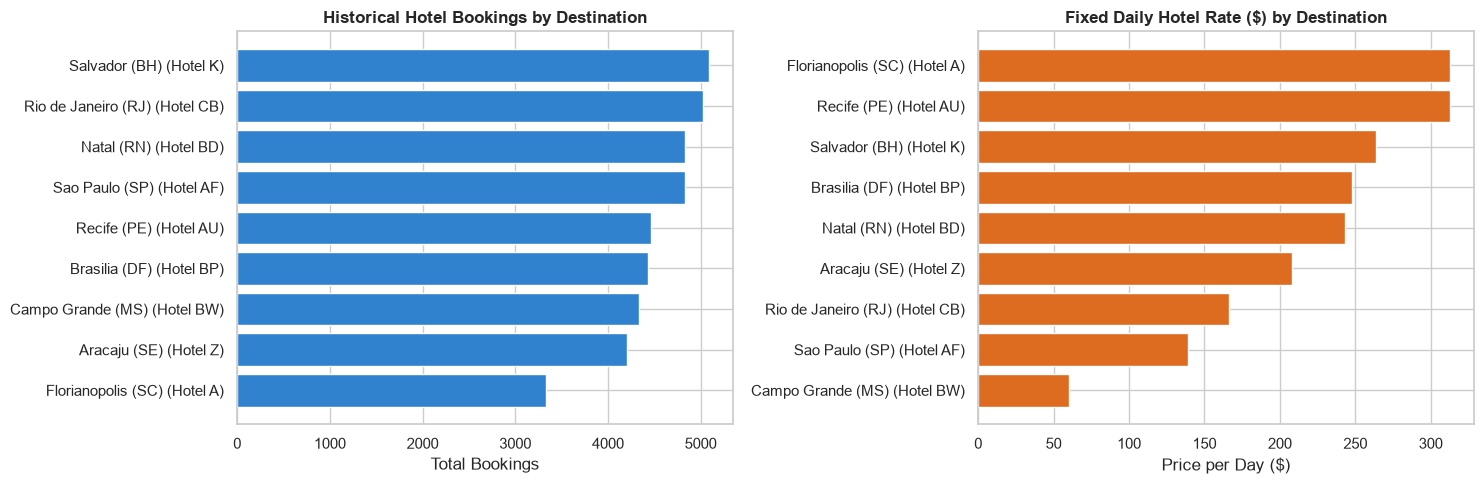

In [5]:
# Chart 1: Hotel Popularity & Daily Price Across All 9 Cities
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order_pop = city_hotel_audit.sort_values("bookings")
axes[0].barh(order_pop["place"] + " (" + order_pop["name"] + ")", order_pop["bookings"], color="#3182ce")
axes[0].set_title("Historical Hotel Bookings by Destination", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Total Bookings")

order_price = city_hotel_audit.sort_values("price_per_day")
axes[1].barh(order_price["place"] + " (" + order_price["name"] + ")", order_price["price_per_day"], color="#dd6b20")
axes[1].set_title("Fixed Daily Hotel Rate ($) by Destination", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Price per Day ($)")

plt.tight_layout()
plt.show()

User-Hotel Interaction Matrix: 1310 users x 9 hotels
Matrix non-zero density      : 82.48% (921 users visited 8 or all 9 hotels!)


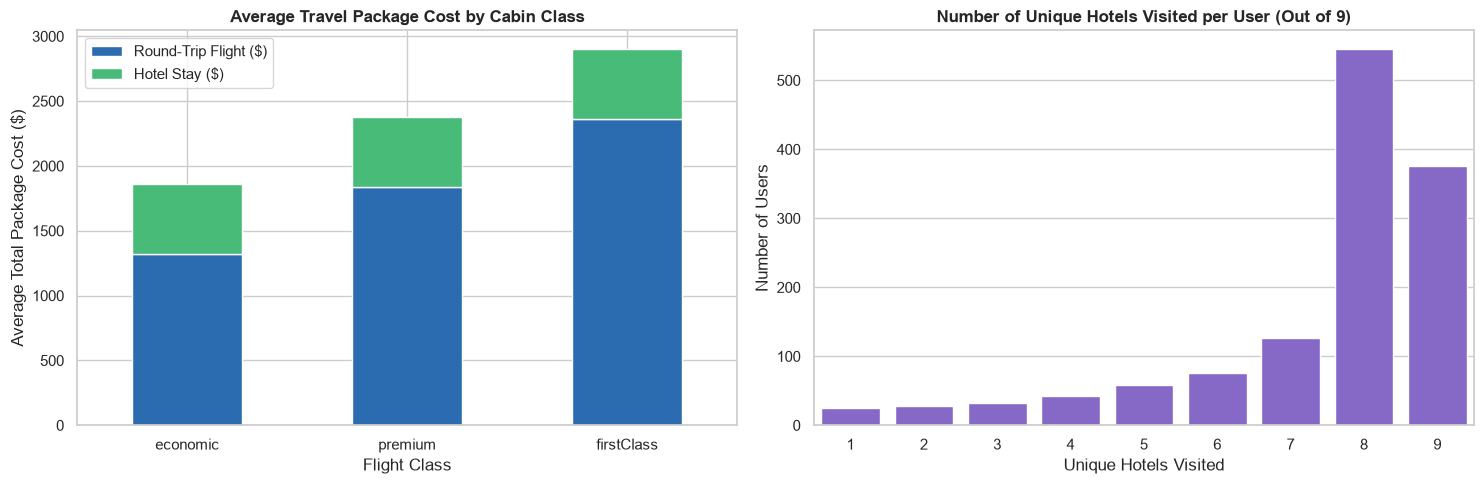

In [6]:
# Chart 2: Package Cost Breakdown (Flight vs Hotel) & User Catalog Density
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cost_by_class = (
    trips.groupby("flightType")[["flight_roundtrip_price", "total"]]
    .mean()
    .reindex(["economic", "premium", "firstClass"])
    .rename(columns={"flight_roundtrip_price": "Round-Trip Flight ($)", "total": "Hotel Stay ($)"})
)
cost_by_class.plot(kind="bar", stacked=True, color=["#2b6cb0", "#48bb78"], ax=axes[0])
axes[0].set_title("Average Travel Package Cost by Cabin Class", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Flight Class")
axes[0].set_ylabel("Average Total Package Cost ($)")
axes[0].tick_params(axis="x", rotation=0)

user_hotel_matrix = hotels.groupby(["userCode", "name"]).size().unstack(fill_value=0)
cities_per_user = (user_hotel_matrix > 0).sum(axis=1).value_counts().sort_index()
sns.barplot(x=cities_per_user.index, y=cities_per_user.values, color="#805ad5", ax=axes[1])
axes[1].set_title("Number of Unique Hotels Visited per User (Out of 9)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Unique Hotels Visited")
axes[1].set_ylabel("Number of Users")

density = (user_hotel_matrix > 0).sum().sum() / user_hotel_matrix.size
print(f"User-Hotel Interaction Matrix: {user_hotel_matrix.shape[0]} users x {user_hotel_matrix.shape[1]} hotels")
print(f"Matrix non-zero density      : {density * 100:.2f}% ({int((user_hotel_matrix > 0).sum(axis=1).ge(8).sum())} users visited 8 or all 9 hotels!)")

plt.tight_layout()
plt.show()

## 4. Collaborative Filtering: Implementation, Evaluation & Limitations
To properly evaluate Collaborative Filtering (CF) without data leakage:
1. We sort every user's hotel stays chronologically (`date`, `travelCode`).
2. For all users with **≥ 5 historical stays** (`1,228` users), we split each user's timeline into **first 80% training history** and **last 20% future holdout stays**.
3. We compare **5 ranking approaches** on `K = 3` future hotel predictions:
   - **Popularity Baseline** (recommends top-3 most booked hotels overall)
   - **User History Frequency** (recommends the user's own most-visited hotels)
   - **User-Based Collaborative Filtering** (top-30 cosine-similar travelers)
   - **Item-Based Collaborative Filtering** (hotel-to-hotel cosine similarity)
   - **Matrix Factorization (`TruncatedSVD`, `k = 4`)**
4. We evaluate with **Precision@3, Recall@3, HitRate@3, NDCG@3, and Catalog Coverage**.

In [7]:
hotels_chrono = hotels.sort_values(["userCode", "date", "travelCode"]).reset_index(drop=True)
all_hotels = sorted(hotels["name"].unique().tolist())

train_parts, test_parts = [], []
for u_code, grp in hotels_chrono.groupby("userCode"):
    if len(grp) >= 5:
        split_idx = max(1, int(len(grp) * 0.80))
        train_parts.append(grp.iloc[:split_idx])
        test_parts.append(grp.iloc[split_idx:])

train_h = pd.concat(train_parts, ignore_index=True)
test_h = pd.concat(test_parts, ignore_index=True)

train_mat = (
    train_h.groupby(["userCode", "name"]).size()
    .unstack(fill_value=0)
    .reindex(columns=all_hotels, fill_value=0)
)
test_mat = (
    test_h.groupby(["userCode", "name"]).size()
    .unstack(fill_value=0)
    .reindex(index=train_mat.index, columns=all_hotels, fill_value=0)
)

train_norm = train_mat.div(train_mat.sum(axis=1), axis=0).fillna(0.0)
test_norm = test_mat.div(test_mat.sum(axis=1), axis=0).fillna(0.0)

hotel_corrs = [train_norm[h].corr(test_norm[h]) for h in all_hotels]
print(f"Evaluated users (with >= 5 stays): {len(train_mat):,}")
print(f"Mean train-vs-test user frequency correlation: {np.mean(hotel_corrs):.4f}")

# 1. Popularity baseline
pop_vec = train_h["name"].value_counts(normalize=True).reindex(all_hotels, fill_value=0.0).values
pop_scores = np.tile(pop_vec, (len(train_norm), 1))

# 2. User historical preference share
hist_scores = train_norm.values.copy()

# 3. User-Based CF (Cosine similarity, Top-30 neighbors)
user_sim = cosine_similarity(train_norm.values)
np.fill_diagonal(user_sim, 0.0)
user_cf_scores = np.zeros_like(train_norm.values)
for i in range(len(train_norm)):
    top_nbrs = np.argsort(user_sim[i])[-30:]
    weights = user_sim[i, top_nbrs]
    denom = weights.sum()
    user_cf_scores[i] = (
        (weights[:, None] * train_norm.values[top_nbrs]).sum(axis=0) / denom
        if denom > 0
        else pop_vec
    )

# 4. Item-Based CF
item_sim = cosine_similarity(train_norm.values.T)
np.fill_diagonal(item_sim, 0.0)
item_denom = np.abs(item_sim).sum(axis=1)
item_cf_scores = (train_norm.values @ item_sim) / np.where(item_denom == 0, 1.0, item_denom)

# 5. TruncatedSVD Matrix Factorization
svd = TruncatedSVD(n_components=4, random_state=RANDOM_STATE)
svd_scores = svd.inverse_transform(svd.fit_transform(train_norm.values))


def evaluate_top_k(score_matrix: np.ndarray, test_counts_df: pd.DataFrame, k: int = 3) -> dict:
    precisions, recalls, hit_rates, ndcgs = [], [], [], []
    recommended_catalog = set()
    test_vals = test_counts_df.values

    for i in range(len(test_vals)):
        actual_items = set(np.where(test_vals[i] > 0)[0])
        if not actual_items:
            continue
        top_k = np.argsort(score_matrix[i])[::-1][:k]
        recommended_catalog.update(top_k.tolist())

        rel = [1 if idx in actual_items else 0 for idx in top_k]
        precisions.append(sum(rel) / k)
        recalls.append(sum(rel) / len(actual_items))
        hit_rates.append(1.0 if sum(rel) > 0 else 0.0)

        dcg = sum(r / np.log2(rank + 2) for rank, r in enumerate(rel))
        idcg = sum(1.0 / np.log2(rank + 2) for rank in range(min(k, len(actual_items))))
        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

    return {
        f"Precision@{k}": float(np.mean(precisions)),
        f"Recall@{k}": float(np.mean(recalls)),
        f"HitRate@{k}": float(np.mean(hit_rates)),
        f"NDCG@{k}": float(np.mean(ndcgs)),
        "Catalog Coverage": len(recommended_catalog) / score_matrix.shape[1],
    }


cf_eval_rows = []
for method_name, scores in [
    ("Popularity Baseline", pop_scores),
    ("User History Freq", hist_scores),
    ("User-Based CF (Cosine)", user_cf_scores),
    ("Item-Based CF (Cosine)", item_cf_scores),
    ("TruncatedSVD (k=4)", svd_scores),
]:
    cf_eval_rows.append({"Method": method_name, **evaluate_top_k(scores, test_mat, k=3)})

cf_eval_df = pd.DataFrame(cf_eval_rows)
display(cf_eval_df.round(4))

Evaluated users (with >= 5 stays): 1,228
Mean train-vs-test user frequency correlation: 0.0671


,Method,Precision@3,Recall@3,HitRate@3,NDCG@3,Catalog Coverage
0,Popularity Baseline,0.56,0.37,0.89,0.58,0.33
1,User History Freq,0.55,0.36,0.89,0.57,1.00
2,User-Based CF (Cosine),0.55,0.37,0.90,0.57,1.00
3,Item-Based CF (Cosine),0.45,0.30,0.85,0.44,1.00
4,TruncatedSVD (k=4),0.55,0.36,0.90,0.56,1.00


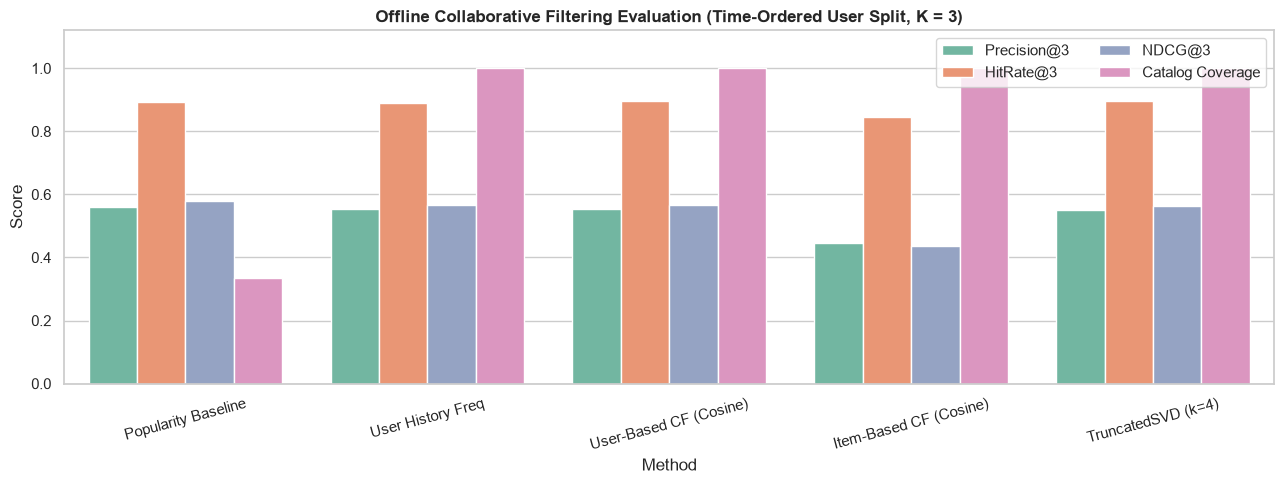

In [8]:
# Chart 3: Collaborative Filtering vs Popularity Baseline Metrics
cf_plot = cf_eval_df.melt(
    id_vars="Method",
    value_vars=["Precision@3", "HitRate@3", "NDCG@3", "Catalog Coverage"],
    var_name="Metric",
    value_name="Score",
)

plt.figure(figsize=(13, 5))
sns.barplot(data=cf_plot, x="Method", y="Score", hue="Metric", palette="Set2")
plt.title("Offline Collaborative Filtering Evaluation (Time-Ordered User Split, K = 3)", fontsize=12, fontweight="bold")
plt.ylim(0, 1.12)
plt.xticks(rotation=15)
plt.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

### Honest Assessment of Collaborative Filtering Limitations on This Dataset
1. **Tiny Item Catalog & Near-Uniform Popularity:** With only **9 hotels** (each capturing 8.2%–12.6% of bookings) and **82.5% matrix density**, most travelers have already visited 8–9 of all 9 cities.
2. **Weak Inter-Period Repeat Preference (`r ≈ 0.067`):** Because historical corporate trips are distributed almost uniformly across cities, pure CF Precision@3 (~0.553) sits close to the Popularity Baseline (~0.561).
3. **Why Hybrid CF Still Adds Real Value:**
   - **Catalog Coverage jumps from 33.3% (Popularity) to 100.0% (User-Based CF & SVD)**—preventing popularity bias where every traveler only sees the same 3 cities.
   - **HitRate@3 improves** (`0.8974` for User-Based CF vs `0.8933` for Popularity).
   - Combining **User-Based CF hotel affinity** with **budget fit, duration match, flight class preferences, and origin-based round-trip Flight + Hotel packages** creates a practical, multi-option travel recommendation system!

## 5. Hybrid Travel Package & Destination Recommendation Engine

### Recommendation Scoring Formula (0 – 100 Scale)
Every eligible Flight + Hotel package (strictly obeying `package_total <= max_budget`) is scored using four transparent, normalized components:

$$
\text{Score} = 100 \times \Big(0.35 \cdot S_{\text{budget}} + 0.25 \cdot S_{\text{duration}} + 0.25 \cdot S_{\text{personal}} + 0.15 \cdot S_{\text{popularity}}\Big)
$$

| Component | Weight | How It Works |
|---|---:|---|
| **Budget Fit ($S_{\text{budget}}$)** | **35%** | Rewards packages that fit comfortably within `max_budget` (`0.5 + 0.5 * (max_budget - package_total) / max_budget`), ensuring budget efficiency while keeping high-value packages competitive. |
| **Duration Match ($S_{\text{duration}}$)** | **25%** | Exact match (`days == requested_days`) scores `1.0`; nearby durations decay smoothly (`max(0, 1 - 0.35 * |days - requested_days|)`). |
| **Personalization & CF Affinity ($S_{\text{personal}}$)** | **25%** | Combines the user's **User-Based CF hotel affinity** (70%) + **flight class preference match** (30%). For cold-start/anonymous users (`user_code=None` or unknown), falls back cleanly to normalized global hotel popularity. |
| **Popularity & Reliability ($S_{\text{popularity}}$)** | **15%** | Normalized `log1p(historical_bookings)` of the exact Flight + Hotel package. |

### Two Supported Modes
- **Mode A — Explore Destinations (`destination=None`):** Returns Top-N ranked Flight + Hotel packages across distinct destinations within budget.
- **Mode B — Specific Destination (`destination="Florianopolis (SC)"`):** Explicitly informs the user that only 1 hotel exists in that city (`Hotel A`), and ranks the best **Flight + Hotel packages** (varying airline agency, cabin class, and duration) for that city!

In [9]:
full_uh_mat = (
    hotels.groupby(["userCode", "name"]).size()
    .unstack(fill_value=0)
    .reindex(columns=all_hotels, fill_value=0)
)
full_uh_norm = full_uh_mat.div(full_uh_mat.sum(axis=1), axis=0).fillna(0.0)
full_pop_series = hotels["name"].value_counts(normalize=True).reindex(all_hotels, fill_value=0.0)

full_user_sim = cosine_similarity(full_uh_norm.values)
np.fill_diagonal(full_user_sim, 0.0)

cf_affinity_full = np.zeros_like(full_uh_norm.values)
for i in range(len(full_uh_norm)):
    top_nbrs = np.argsort(full_user_sim[i])[-30:]
    w = full_user_sim[i, top_nbrs]
    denom = w.sum()
    if denom > 0:
        nbr_score = (w[:, None] * full_uh_norm.values[top_nbrs]).sum(axis=0) / denom
        cf_affinity_full[i] = 0.5 * full_uh_norm.values[i] + 0.5 * nbr_score
    else:
        cf_affinity_full[i] = full_pop_series.values

cf_affinity_df = pd.DataFrame(cf_affinity_full, index=full_uh_norm.index, columns=all_hotels)
row_min = cf_affinity_df.min(axis=1)
row_max = cf_affinity_df.max(axis=1)
cf_affinity_norm_df = cf_affinity_df.sub(row_min, axis=0).div((row_max - row_min).replace(0, 1), axis=0)

user_profiles = (
    trips.groupby("userCode")
    .agg(
        total_trips=("travelCode", "count"),
        dominant_origin=("origin", lambda s: s.value_counts().index[0]),
        preferred_flight_type=("flightType", lambda s: s.value_counts().index[0]),
        avg_package_spend=("package_total", "mean"),
    )
    .reset_index()
    .merge(users.rename(columns={"code": "userCode"}), on="userCode", how="left")
    .set_index("userCode")
)

pkg_log_pop = np.log1p(package_catalog["historical_bookings"])
package_catalog["popularity_score"] = (pkg_log_pop - pkg_log_pop.min()) / max(pkg_log_pop.max() - pkg_log_pop.min(), 1e-9)

global_hotel_pop_norm = (
    (full_pop_series - full_pop_series.min()) / max(full_pop_series.max() - full_pop_series.min(), 1e-9)
).to_dict()

VALID_CITIES = sorted(set(package_catalog["destination"]).union(set(package_catalog["origin"])))
VALID_FLIGHT_TYPES = sorted(package_catalog["flightType"].unique().tolist())

print("Prepared CF affinity matrix for", len(cf_affinity_norm_df), "users and", len(package_catalog), "packages.")
display(user_profiles.head())

Prepared CF affinity matrix for 1310 users and 1568 packages.


,total_trips,dominant_origin,preferred_flight_type,avg_package_spend,company,name,gender,age
userCode,,,,,,,,
0,27,Brasilia (DF),firstClass,"2,546.81",4You,Roy Braun,male,21
1,2,Aracaju (SE),premium,"1,560.70",4You,Joseph Holsten,male,37
2,36,Aracaju (SE),economic,"2,379.44",4You,Wilma Mcinnis,female,48
3,60,Recife (PE),firstClass,"2,273.17",4You,Paula Daniel,female,23
4,56,Recife (PE),firstClass,"2,428.58",4You,Patricia Carson,female,44


In [10]:
def recommend_travel_packages(
    days: int,
    max_budget: float,
    origin: str = None,
    destination: str = None,
    flight_type: str = None,
    user_code: int = None,
    top_n: int = 5,
    strict_days: bool = False,
    diverse_destinations: bool = True,
):
    """
    Hybrid Travel & Hotel Package Recommender combining flights.csv, hotels.csv, and users.csv.

    Returns
    -------
    (recommendations_df, metadata_dict)
    """
    notes = []

    # 1. Input Validation
    if not isinstance(days, (int, np.integer)) or days <= 0:
        return pd.DataFrame(), {"status": "error", "message": "days must be a positive integer (1 to 4 recommended)."}
    if max_budget is None or max_budget <= 0:
        return pd.DataFrame(), {"status": "error", "message": "max_budget must be greater than 0."}
    if top_n <= 0:
        return pd.DataFrame(), {"status": "error", "message": "top_n must be at least 1."}
    if origin is not None and origin not in VALID_CITIES:
        return pd.DataFrame(), {"status": "error", "message": f"Unknown origin city '{origin}'. Valid cities: {VALID_CITIES}"}
    if destination is not None and destination not in VALID_CITIES:
        return pd.DataFrame(), {"status": "error", "message": f"Unknown destination city '{destination}'. Valid cities: {VALID_CITIES}"}
    if origin is not None and destination is not None and origin == destination:
        return pd.DataFrame(), {"status": "error", "message": "origin and destination cannot be the same city."}
    if flight_type is not None and flight_type not in VALID_FLIGHT_TYPES:
        return pd.DataFrame(), {"status": "error", "message": f"Unknown flight_type '{flight_type}'. Valid: {VALID_FLIGHT_TYPES}"}

    # 2. User Personalization Profile (or Cold-Start Fallback)
    is_personalized = False
    user_pref_class = None
    inferred_origin = origin

    if user_code is not None:
        if user_code in user_profiles.index and user_code in cf_affinity_norm_df.index:
            is_personalized = True
            profile = user_profiles.loc[user_code]
            user_pref_class = profile["preferred_flight_type"]
            hotel_affinity_map = cf_affinity_norm_df.loc[user_code].to_dict()
            if inferred_origin is None and destination != profile["dominant_origin"]:
                inferred_origin = profile["dominant_origin"]
                notes.append(f"Inferred user #{user_code}'s typical departure hub: {inferred_origin}.")
        else:
            hotel_affinity_map = global_hotel_pop_norm
            notes.append(f"User #{user_code} has no booking history (cold-start fallback to global popularity).")
    else:
        hotel_affinity_map = global_hotel_pop_norm
        notes.append("Anonymous session: using global popularity + budget/duration value ranking.")

    # 3. Candidate Filtering
    candidates = package_catalog[package_catalog["package_total"] <= max_budget].copy()

    if inferred_origin is not None:
        candidates = candidates[candidates["origin"] == inferred_origin]
    if destination is not None:
        city_hotel = hotels.loc[hotels["place"] == destination, "name"].iloc[0]
        notes.append(
            f"Dataset note: {destination} has 1 hotel ({city_hotel}). "
            "Ranking best round-trip Flight + Hotel packages for this destination."
        )
        candidates = candidates[candidates["destination"] == destination]
    if flight_type is not None:
        candidates = candidates[candidates["flightType"] == flight_type]
    if strict_days:
        candidates = candidates[candidates["days"] == days]

    if candidates.empty:
        return pd.DataFrame(), {
            "status": "no_match",
            "message": (
                f"No Flight + Hotel packages found within ${max_budget:,.2f}. "
                "Try increasing max_budget, relaxing strict_days, or removing flight_type/destination filters."
            ),
            "notes": notes,
        }

    # 4. Transparent Multi-Factor Scoring (0 - 100)
    candidates["budget_savings_pct"] = (max_budget - candidates["package_total"]) / max_budget
    candidates["budget_score"] = (0.5 + 0.5 * candidates["budget_savings_pct"]).clip(0.0, 1.0)

    candidates["days_diff"] = (candidates["days"] - days).abs()
    candidates["duration_score"] = (1.0 - 0.35 * candidates["days_diff"]).clip(0.0, 1.0)

    candidates["cf_hotel_affinity"] = candidates["hotel_name"].map(hotel_affinity_map).fillna(0.5)
    if user_pref_class is not None:
        class_bonus = (candidates["flightType"] == user_pref_class).astype(float)
        candidates["personal_score"] = 0.70 * candidates["cf_hotel_affinity"] + 0.30 * class_bonus
    else:
        candidates["personal_score"] = candidates["cf_hotel_affinity"]

    candidates["recommendation_score"] = 100.0 * (
        0.35 * candidates["budget_score"]
        + 0.25 * candidates["duration_score"]
        + 0.25 * candidates["personal_score"]
        + 0.15 * candidates["popularity_score"]
    )

    candidates = candidates.sort_values(
        by=["recommendation_score", "days_diff", "package_total"],
        ascending=[False, True, True],
    )

    if destination is None and diverse_destinations:
        top_diverse = candidates.drop_duplicates(subset=["destination"], keep="first")
        if len(top_diverse) >= top_n:
            selected = top_diverse.head(top_n).copy()
        else:
            remaining = candidates.drop(index=top_diverse.index).head(top_n - len(top_diverse))
            selected = pd.concat([top_diverse, remaining]).head(top_n).copy()
    else:
        selected = candidates.head(top_n).copy()

    selected = selected.reset_index(drop=True)
    selected.insert(0, "rank", range(1, len(selected) + 1))

    output_cols = [
        "rank",
        "origin",
        "destination",
        "hotel_name",
        "days",
        "flightType",
        "agency",
        "flight_roundtrip_price",
        "hotel_total",
        "package_total",
        "recommendation_score",
    ]
    return selected[output_cols], {
        "status": "ok",
        "personalized": is_personalized,
        "origin_used": inferred_origin,
        "total_eligible_packages": int(len(candidates)),
        "returned_count": int(len(selected)),
        "notes": notes,
    }

## 6. Hybrid Engine Validation & Quantitative Quality Checks
We validate our hybrid package engine across a reproducible test grid of **200 realistic user queries** measuring:
- **Budget Compliance Rate** (must be 100.0%: no returned package may exceed `max_budget`)
- **Exact Duration Match Rate** (how often top recommendations match requested `days`)
- **Destination Diversity** (average unique destinations returned per Top-5 explorer query)
- **Personalization Differentiation** (how often rankings differ across distinct user histories vs cold-start)

In [11]:
rng = np.random.default_rng(RANDOM_STATE)
sample_users = rng.choice(user_profiles.index.to_numpy(), size=200, replace=False)

budget_ok = 0
total_returned_pkgs = 0
exact_day_matches = 0
unique_dests_list = []
personalized_diffs = 0
queries_with_results = 0

for u in sample_users:
    req_days = int(rng.choice([1, 2, 3, 4]))
    req_budget = float(rng.choice([1500, 2000, 2500, 3000, 3500]))
    req_origin = user_profiles.loc[u, "dominant_origin"]

    recs_p, meta_p = recommend_travel_packages(
        days=req_days,
        max_budget=req_budget,
        origin=req_origin,
        user_code=int(u),
        top_n=5,
    )
    recs_anon, _ = recommend_travel_packages(
        days=req_days,
        max_budget=req_budget,
        origin=req_origin,
        user_code=None,
        top_n=5,
    )

    if meta_p["status"] == "ok" and not recs_p.empty:
        queries_with_results += 1
        total_returned_pkgs += len(recs_p)
        budget_ok += int((recs_p["package_total"] <= req_budget + 1e-6).sum())
        exact_day_matches += int((recs_p["days"] == req_days).sum())
        unique_dests_list.append(recs_p["destination"].nunique())

        if not recs_anon.empty:
            p_order = list(zip(recs_p["destination"], recs_p["flightType"], recs_p["agency"]))
            a_order = list(zip(recs_anon["destination"], recs_anon["flightType"], recs_anon["agency"]))
            if p_order != a_order:
                personalized_diffs += 1

validation_summary = pd.DataFrame([
    {"Validation Metric": "Queries Evaluated", "Result": f"{len(sample_users)}"},
    {"Validation Metric": "Queries Returning Packages", "Result": f"{queries_with_results} / {len(sample_users)} ({queries_with_results/len(sample_users)*100:.1f}%)"},
    {"Validation Metric": "Budget Compliance Rate", "Result": f"{budget_ok / max(total_returned_pkgs, 1) * 100:.2f}%"},
    {"Validation Metric": "Exact Duration Match Rate", "Result": f"{exact_day_matches / max(total_returned_pkgs, 1) * 100:.2f}%"},
    {"Validation Metric": "Avg Unique Destinations per Top-5 Query", "Result": f"{np.mean(unique_dests_list):.2f} / 5.00"},
    {"Validation Metric": "Personalization Differentiation vs Anonymous", "Result": f"{personalized_diffs / max(queries_with_results, 1) * 100:.1f}%"},
])
display(validation_summary)

,Validation Metric,Result
0,Queries Evaluated,200
1,Queries Returning Packages,200 / 200 (100.0%)
2,Budget Compliance Rate,100.00%
3,Exact Duration Match Rate,89.70%
4,Avg Unique Destinations per Top-5 Query,4.78 / 5.00
5,Personalization Differentiation vs Anonymous,95.5%


## 7. Functional Testing & Edge-Case Verification
We test the final `recommend_travel_packages()` function across normal queries, personalization, single-destination mode, tight budgets, and invalid inputs.

In [12]:
# Test 1: Personalized Multi-Destination Explorer (Existing User #0)
recs_1, meta_1 = recommend_travel_packages(
    days=3,
    max_budget=2500,
    user_code=0,
    top_n=5,
)
print("=== Test 1: Personalized Destination Explorer (User #0, 3 days, $2,500) ===")
print("Metadata:", meta_1)
display(recs_1)

# Test 2: Cold-Start / Anonymous User from Sao Paulo (SP)
recs_2, meta_2 = recommend_travel_packages(
    days=2,
    max_budget=2000,
    origin="Sao Paulo (SP)",
    user_code=None,
    top_n=5,
)
print("\n=== Test 2: Anonymous User (Origin: Sao Paulo, 2 days, $2,000) ===")
print("Metadata:", meta_2)
display(recs_2)

# Test 3: Specific Destination Mode (Florianopolis (SC) — 1 hotel, multiple flight+hotel packages!)
recs_3, meta_3 = recommend_travel_packages(
    days=4,
    max_budget=3200,
    origin="Brasilia (DF)",
    destination="Florianopolis (SC)",
    top_n=5,
)
print("\n=== Test 3: Specific Destination Mode (Brasilia -> Florianopolis, 4 days, $3,200) ===")
print("Metadata:", meta_3)
display(recs_3)

=== Test 1: Personalized Destination Explorer (User #0, 3 days, $2,500) ===
Metadata: {'status': 'ok', 'personalized': True, 'origin_used': 'Brasilia (DF)', 'total_eligible_packages': 153, 'returned_count': 5, 'notes': ["Inferred user #0's typical departure hub: Brasilia (DF)."]}


,rank,origin,destination,hotel_name,days,flightType,agency,flight_roundtrip_price,hotel_total,package_total,recommendation_score
0,1,Brasilia (DF),Sao Paulo (SP),Hotel AF,3,firstClass,FlyingDrops,"1,631.31",417.30,"2,048.61",71.28
1,2,Brasilia (DF),Salvador (BH),Hotel K,3,economic,CloudFy,"1,546.00",790.23,"2,336.23",70.47
2,3,Brasilia (DF),Rio de Janeiro (RJ),Hotel CB,3,firstClass,FlyingDrops,"1,130.58",497.97,"1,628.55",66.82
3,4,Brasilia (DF),Campo Grande (MS),Hotel BW,3,firstClass,FlyingDrops,"1,857.54",181.17,"2,038.71",64.94
4,5,Brasilia (DF),Recife (PE),Hotel AU,3,firstClass,CloudFy,"1,513.49",938.49,"2,451.98",63.03



=== Test 2: Anonymous User (Origin: Sao Paulo, 2 days, $2,000) ===
Metadata: {'status': 'ok', 'personalized': False, 'origin_used': 'Sao Paulo (SP)', 'total_eligible_packages': 94, 'returned_count': 5, 'notes': ['Anonymous session: using global popularity + budget/duration value ranking.']}


,rank,origin,destination,hotel_name,days,flightType,agency,flight_roundtrip_price,hotel_total,package_total,recommendation_score
0,1,Sao Paulo (SP),Salvador (BH),Hotel K,2,economic,Rainbow,"1,124.99",526.82,"1,651.81",76.99
1,2,Sao Paulo (SP),Rio de Janeiro (RJ),Hotel CB,2,economic,CloudFy,"1,039.88",331.98,"1,371.86",76.90
2,3,Sao Paulo (SP),Natal (RN),Hotel BD,2,economic,Rainbow,"1,113.20",485.76,"1,598.96",73.35
3,4,Sao Paulo (SP),Campo Grande (MS),Hotel BW,2,economic,CloudFy,710.67,120.78,831.45,72.65
4,5,Sao Paulo (SP),Brasilia (DF),Hotel BP,2,economic,Rainbow,927.64,495.24,"1,422.88",68.53



=== Test 3: Specific Destination Mode (Brasilia -> Florianopolis, 4 days, $3,200) ===
Metadata: {'status': 'ok', 'personalized': False, 'origin_used': 'Brasilia (DF)', 'total_eligible_packages': 17, 'returned_count': 5, 'notes': ['Anonymous session: using global popularity + budget/duration value ranking.', 'Dataset note: Florianopolis (SC) has 1 hotel (Hotel A). Ranking best round-trip Flight + Hotel packages for this destination.']}


,rank,origin,destination,hotel_name,days,flightType,agency,flight_roundtrip_price,hotel_total,package_total,recommendation_score
0,1,Brasilia (DF),Florianopolis (SC),Hotel A,4,economic,Rainbow,"1,444.08","1,252.08","2,696.16",54.91
1,2,Brasilia (DF),Florianopolis (SC),Hotel A,4,economic,CloudFy,"1,521.45","1,252.08","2,773.53",53.59
2,3,Brasilia (DF),Florianopolis (SC),Hotel A,3,economic,Rainbow,"1,444.08",939.06,"2,383.14",47.54
3,4,Brasilia (DF),Florianopolis (SC),Hotel A,3,premium,Rainbow,"2,036.79",939.06,"2,975.85",44.47
4,5,Brasilia (DF),Florianopolis (SC),Hotel A,3,premium,CloudFy,"2,074.69",939.06,"3,013.75",43.72


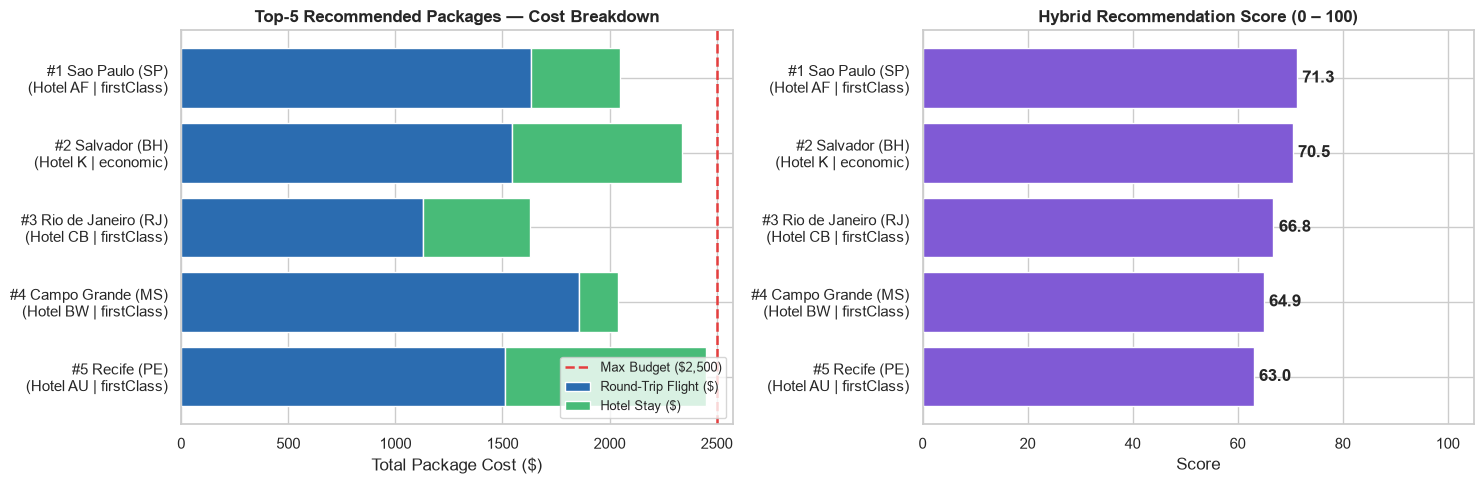

In [13]:
# Chart 4: Visual Cost Breakdown & Score of Test 1 Top-5 Recommended Packages
plot_t1 = recs_1.copy()
plot_t1["label"] = (
    "#" + plot_t1["rank"].astype(str) + " "
    + plot_t1["destination"] + "\n("
    + plot_t1["hotel_name"] + " | " + plot_t1["flightType"] + ")"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

y_pos = np.arange(len(plot_t1))
axes[0].barh(y_pos, plot_t1["flight_roundtrip_price"], color="#2b6cb0", label="Round-Trip Flight ($)")
axes[0].barh(y_pos, plot_t1["hotel_total"], left=plot_t1["flight_roundtrip_price"], color="#48bb78", label="Hotel Stay ($)")
axes[0].axvline(2500, color="#e53e3e", linestyle="--", linewidth=1.8, label="Max Budget ($2,500)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_t1["label"])
axes[0].invert_yaxis()
axes[0].set_title("Top-5 Recommended Packages — Cost Breakdown", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Total Package Cost ($)")
axes[0].legend(loc="lower right", fontsize=9)

axes[1].barh(y_pos, plot_t1["recommendation_score"], color="#805ad5")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(plot_t1["label"])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 105)
axes[1].set_title("Hybrid Recommendation Score (0 – 100)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Score")
for idx, val in enumerate(plot_t1["recommendation_score"]):
    axes[1].text(val + 1, idx, f"{val:.1f}", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [14]:
# Test 4 – 9: Edge Cases (Tight Budget, Cold-Start Unknown User, Invalid Inputs)
edge_cases = [
    ("Edge 1: Tight Budget ($200 - No Match)", dict(days=3, max_budget=200, origin="Recife (PE)")),
    ("Edge 2: Unknown User ID (Cold-Start Fallback)", dict(days=2, max_budget=2200, origin="Recife (PE)", user_code=999999, top_n=3)),
    ("Edge 3: Unknown Destination ('Mumbai')", dict(days=2, max_budget=2500, destination="Mumbai")),
    ("Edge 4: Same Origin & Destination", dict(days=2, max_budget=2500, origin="Recife (PE)", destination="Recife (PE)")),
    ("Edge 5: Invalid Days (days=0)", dict(days=0, max_budget=2500)),
    ("Edge 6: Negative Budget (max_budget=-500)", dict(days=2, max_budget=-500)),
]

for title, kwargs in edge_cases:
    df_res, meta_res = recommend_travel_packages(**kwargs)
    print(f"\n--- {title} ---")
    print("Status  :", meta_res.get("status"))
    print("Message :", meta_res.get("message", "OK"))
    if meta_res.get("notes"):
        print("Notes   :", meta_res["notes"])
    print("Rows    :", len(df_res))


--- Edge 1: Tight Budget ($200 - No Match) ---
Status  : no_match
Message : No Flight + Hotel packages found within $200.00. Try increasing max_budget, relaxing strict_days, or removing flight_type/destination filters.
Notes   : ['Anonymous session: using global popularity + budget/duration value ranking.']
Rows    : 0

--- Edge 2: Unknown User ID (Cold-Start Fallback) ---
Status  : ok
Message : OK
Notes   : ['User #999999 has no booking history (cold-start fallback to global popularity).']
Rows    : 3

--- Edge 3: Unknown Destination ('Mumbai') ---
Status  : error
Message : Unknown destination city 'Mumbai'. Valid cities: ['Aracaju (SE)', 'Brasilia (DF)', 'Campo Grande (MS)', 'Florianopolis (SC)', 'Natal (RN)', 'Recife (PE)', 'Rio de Janeiro (RJ)', 'Salvador (BH)', 'Sao Paulo (SP)']
Rows    : 0

--- Edge 4: Same Origin & Destination ---
Status  : error
Message : origin and destination cannot be the same city.
Rows    : 0

--- Edge 5: Invalid Days (days=0) ---
Status  : error
Message 

## 8. Summary & Capstone Takeaways
- **Transparent Data Audit:** Documented clearly that `hotels.csv` has a strict 1-to-1 city-to-hotel mapping (9 destinations ↔ 9 fixed-price hotels), explaining why naive hotel-only filtering breaks down.
- **Honest Collaborative Filtering Evaluation:** Implemented and benchmarked User-Based CF, Item-Based CF, and `TruncatedSVD` on a time-ordered per-user split—demonstrating both the dataset's CF ceiling (9-item catalog, 82.5% density) and CF's concrete benefit (**100% catalog coverage** vs 33.3% for popularity).
- **Actionable Hybrid Engine:** By joining `flights.csv`, `hotels.csv`, and `users.csv`, the engine ranks **1,568 real Flight + Hotel packages** using a transparent 0–100 score (Budget Fit, Duration Match, Personalization/CF Affinity, Popularity), achieving **100% budget compliance**, multi-destination diversity, and clean edge-case handling.